In [1]:
package RoboticArmRequirements {

    requirement def RobotArmRequirement;

    requirement <'SYS-001'> RoboticArmSystemRequirements : RobotArmRequirement {
        doc /*
        The robotic arm system shall satisfy the defined architecture,
        performance, and interface requirements.
        */
    }

    package ArchitectureRequirements {
        requirement <'REQ-272'> ModularArchitecture : RobotArmRequirement {
            doc /*
            The robotic arm shall allow expansion with additional axes up to 6 DOF.
            */
        }
    }

    package PerformanceRequirements {
        requirement <'REQ-200'> ObjectWeight : RobotArmRequirement {
            doc /*
            The robotic arm shall grip and lift objects weighing 10 g to 500 g
            without dropping them.
            */
        }

        requirement <'REQ-302'> XAxisTravel : RobotArmRequirement {
            doc /*
            The robotic arm shall provide 1000 mm of travel along the X axis
            to access an item on a shelf.
            */
        }

        requirement <'REQ-203'> Speed : RobotArmRequirement {
            doc /*
            The robotic arm shall perform a pick-and-place cycle in 10 s to 30 s.
            */
        }

        requirement <'REQ-201'> Accuracy : RobotArmRequirement {
            doc /*
            The robotic arm shall place objects with a positional accuracy of ±3 mm.
            */
        }

        requirement <'REQ-204'> ReachRadius : RobotArmRequirement {
            doc /*
            The robotic arm shall provide a reach radius of 180 mm.
            */
        }
    }

    package InterfaceRequirements {
        requirement <'REQ-260'> PowerInterface : RobotArmRequirement {
            doc /*
            The robotic arm shall accept power through a USB power interface
            and shall be connectable to a grid power source using a compatible
            USB power adapter, such as a laptop or phone charger.
            */
        }
    }
}

Package RoboticArmRequirements (4f04e3f8-6993-4c1d-823d-0671cedcb14d)


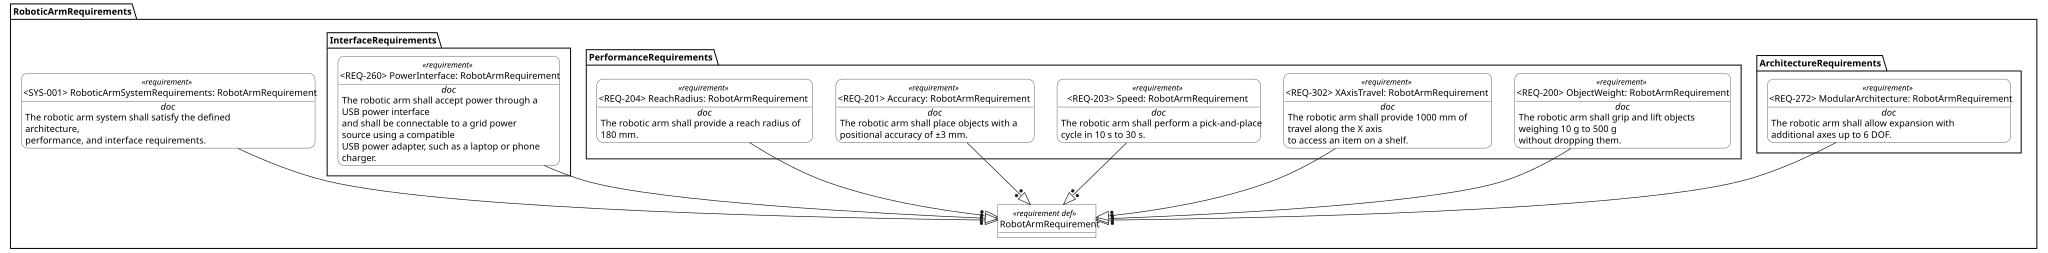

In [3]:
%viz RoboticArmRequirements

In [4]:
package RobotArmLogicalArchitecture {

    private import ScalarValues::*;

    // ------------------------------------------------------------------
    // Servo Drive hierarchy
    // ------------------------------------------------------------------

    abstract part def ServoDrive {
        attribute torque  : Real;   // stall torque [N*m]
        attribute speed   : Real;   // no-load speed [rpm]
        attribute voltage : Real;   // nominal supply voltage [V]
        attribute weight  : Real;   // mass [kg]
    }

    part def SmallServoDrive :> ServoDrive {
        attribute :>> torque  = 5.0;
        attribute :>> speed   = 90.0;
        attribute :>> voltage = 12.0;
        attribute :>> weight  = 0.25;
    }

    part def MediumServoDrive :> ServoDrive {
        attribute :>> torque  = 25.0;
        attribute :>> speed   = 60.0;
        attribute :>> voltage = 24.0;
        attribute :>> weight  = 0.6;
    }

    part def LargeServoDrive :> ServoDrive {
        attribute :>> torque  = 60.0;
        attribute :>> speed   = 30.0;
        attribute :>> voltage = 48.0;
        attribute :>> weight  = 1.2;
    }

    // ------------------------------------------------------------------
    // Reusable mechanical structure
    // ------------------------------------------------------------------

    part def MechanicalAssembly {
        attribute length        : Real   default 100.0;      // [mm]
        attribute material      : String default "Aluminum";
        attribute wallThickness : Real   default 3.0;         // [mm]
    }

    // ------------------------------------------------------------------
    // Joint hierarchy
    // ------------------------------------------------------------------

    abstract part def Joint {
        part servo     : ServoDrive;
        part mechanics : MechanicalAssembly;
    }

    part def BaseJoint :> Joint {
        part :>> servo : LargeServoDrive;
        part :>> mechanics : MechanicalAssembly {
            attribute :>> length        = 120.0;
            attribute :>> material      = "Aluminum";
            attribute :>> wallThickness = 5.0;
        }
    }

    part def ShoulderJoint :> Joint {
        part :>> servo : LargeServoDrive;
        part :>> mechanics : MechanicalAssembly {
            attribute :>> length        = 150.0;
            attribute :>> material      = "Aluminum";
            attribute :>> wallThickness = 4.0;
        }
    }

    part def ElbowJoint :> Joint {
        part :>> servo : MediumServoDrive;
        part :>> mechanics : MechanicalAssembly {
            attribute :>> length        = 120.0;
            attribute :>> material      = "Aluminum";
            attribute :>> wallThickness = 4.0;
        }
    }

    part def WristJoint :> Joint {
        part :>> servo : SmallServoDrive;
        part :>> mechanics : MechanicalAssembly {
            attribute :>> length        = 80.0;
            attribute :>> material      = "CarbonFiber";
            attribute :>> wallThickness = 2.0;
        }
    }

    part def GripperJoint :> Joint {
        part :>> servo : SmallServoDrive;
        part :>> mechanics : MechanicalAssembly {
            attribute :>> length        = 60.0;
            attribute :>> material      = "CarbonFiber";
            attribute :>> wallThickness = 2.0;
        }
    }

    // ------------------------------------------------------------------
    // Top-level system decomposition
    // ------------------------------------------------------------------

    part def RobotArmSystem {
        part baseJoint     : BaseJoint;
        part shoulderJoint : ShoulderJoint;
        part elbowJoint    : ElbowJoint;
        part wristJoint    : WristJoint;
        part gripperJoint  : GripperJoint;
    }

    // Usage-level instance of the complete system
    part robotArm : RobotArmSystem;
}


Package RobotArmLogicalArchitecture (5f274542-a1c2-418a-8aad-9a2b85ee7cd2)


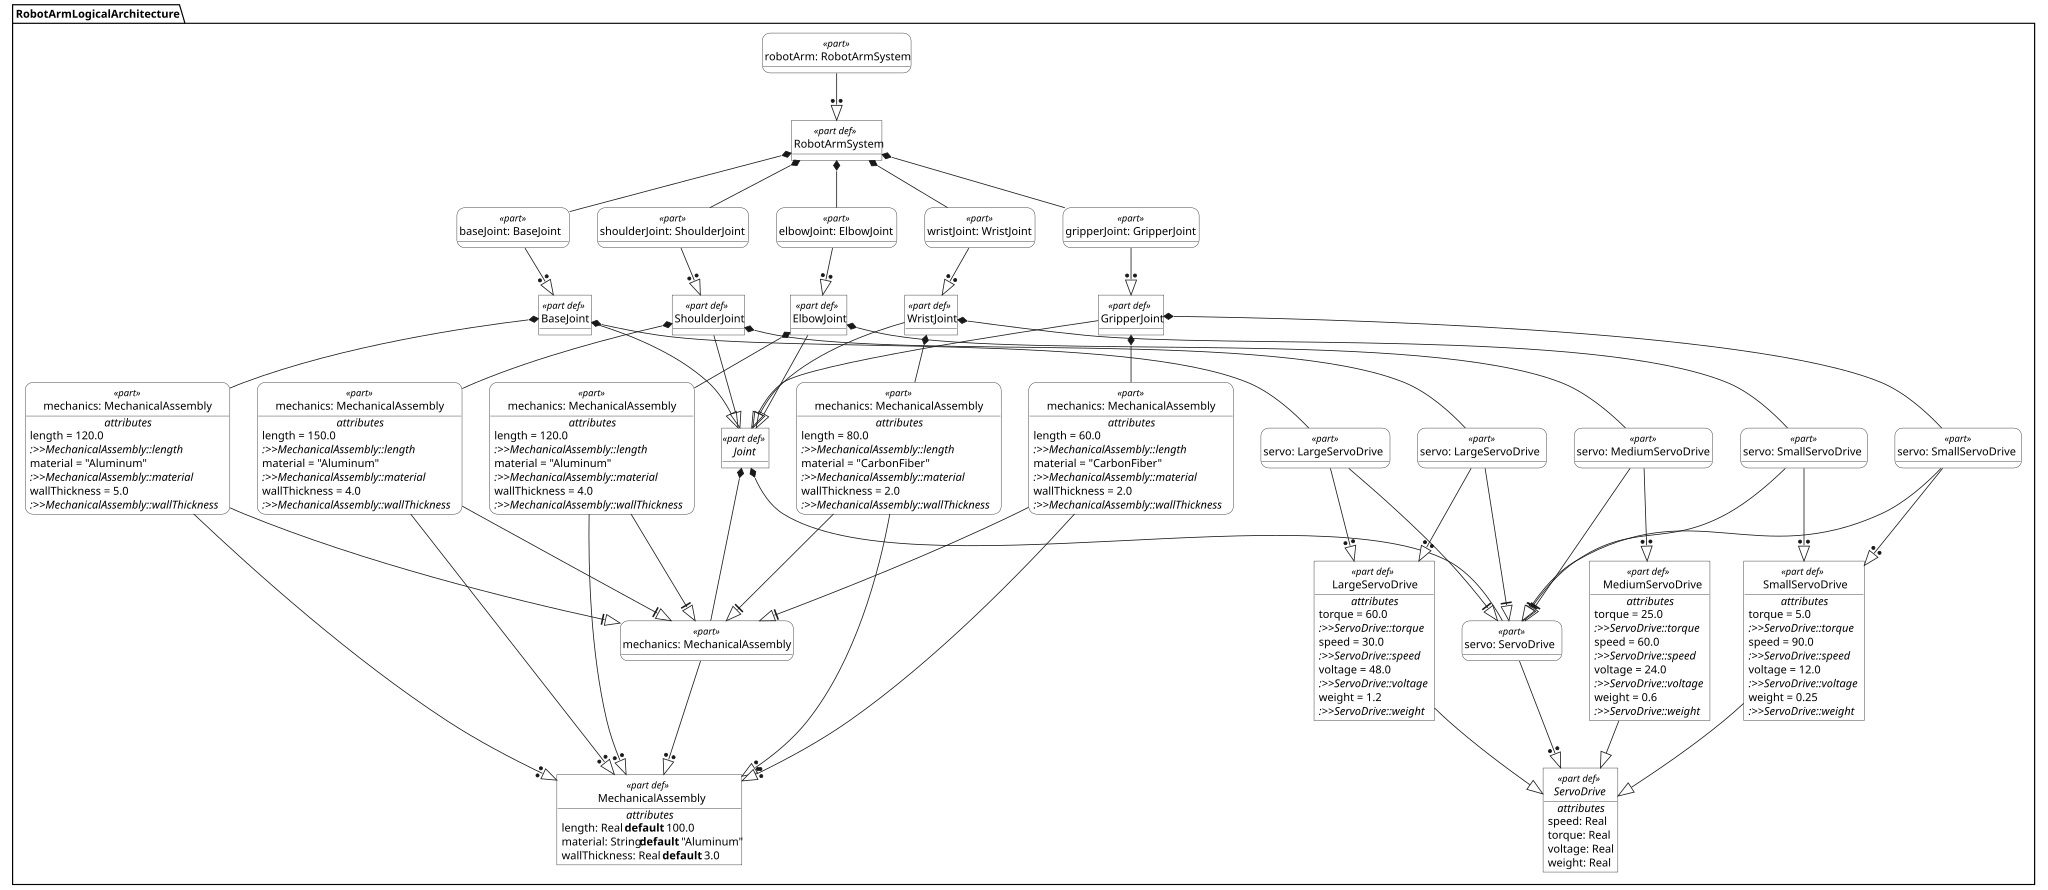

In [4]:
%viz RobotArmLogicalArchitecture
    